# Inverse Problems 2026 - Exercise 2 (home exercises)

___
In the following exercises you should use the given data `y`, forward operator `A` and ground truth `gt`.
___

In [1]:
import numpy as np
import scipy.linalg as la

n = 100
x = np.linspace(0, 1, n)

psf = np.array([0.02, 0.08, 0.13, 0.17, 0.19, 0.17, 0.13, 0.08, 0.02])
A = la.convolution_matrix(psf, n, mode="same")
gt = np.array([0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
        0.  , 1.5 , 1.5 , 1.5 , 0.  , 0.  , 0.  , 0.  , 0.  , 1.3 , 1.3 ,
        1.3 , 1.3 , 1.3 , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
        0.  , 0.  , 0.02, 0.07, 0.12, 0.17, 0.22, 0.27, 0.32, 0.37, 0.42,
        0.47, 0.52, 0.57, 0.62, 0.67, 0.72, 0.78, 0.83, 0.88, 0.93, 0.98,
        0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
        0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 1.  , 1.  ,
        1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 0.  , 0.  , 0.  ,
        0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
        0.  ])
y = np.array([ 1.98e-02, -6.76e-02,  4.88e-02,  6.11e-02, -1.27e-01, -8.46e-02,
        8.31e-03, -2.06e-02, -1.09e-03, -5.54e-02,  9.36e-02,  4.01e-01,
        8.95e-01,  1.39e+00,  1.18e+00,  5.54e-01,  1.76e-01, -6.23e-02,
        8.87e-02,  3.00e-01,  7.60e-01,  1.12e+00,  1.38e+00,  1.26e+00,
        9.69e-01,  5.05e-01,  1.66e-01,  2.38e-02,  2.68e-02,  2.80e-02,
        1.39e-01, -2.64e-02, -3.33e-02, -5.27e-02,  4.52e-02,  9.78e-02,
        5.39e-02,  5.47e-02,  1.06e-01,  2.52e-01,  3.08e-01,  3.46e-01,
        3.17e-01,  4.26e-01,  4.69e-01,  5.26e-01,  6.18e-01,  6.26e-01,
        7.06e-01,  7.17e-01,  7.81e-01,  8.54e-01,  7.68e-01,  8.68e-01,
        6.93e-01,  3.51e-01,  8.15e-02,  9.72e-02, -5.63e-02,  6.29e-02,
        -1.09e-01, -2.18e-02,  1.06e-02,  3.81e-02,  4.62e-02,  5.16e-02,
        -2.27e-02, -3.01e-02,  5.58e-02, -1.24e-02, -8.29e-02, -7.37e-02,
        -5.98e-02,  5.66e-02,  2.43e-01,  6.39e-01,  8.71e-01,  1.01e+00,
        1.04e+00,  9.80e-01,  1.03e+00,  9.57e-01,  9.76e-01,  9.51e-01,
        6.89e-01,  4.38e-01,  7.06e-02,  8.12e-04,  3.12e-02,  2.90e-02,
        4.33e-02, -6.40e-03, -2.75e-02, -5.18e-03, -1.10e-01, -9.41e-02,
        -8.60e-02, -6.48e-02,  2.60e-02, -5.89e-02])

## Task 1 (Tikhonov regularization)
Using the given forward matrix `A` and vector `y`, solve the Tikhonov regularized solution for regularization parameters $\alpha = 0.01, 0.1$ and $1$ and plot the result.

Finding the solution for a = 0.01.
Finding the solution for a = 0.1.
Finding the solution for a = 1.0.


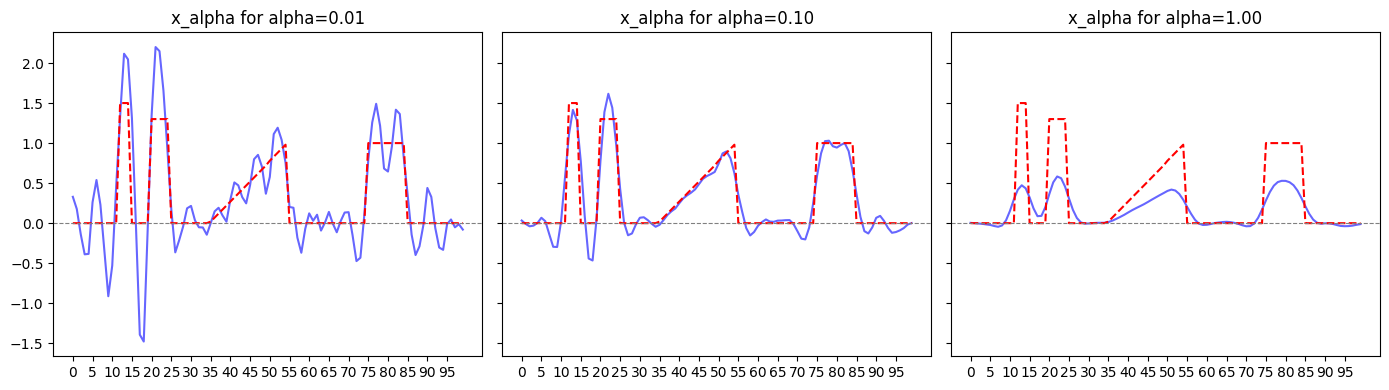

In [49]:
# import matlplotlib
import matplotlib.pyplot as plt

def tikho_regusol(A, y, alpha):
  At = A.T
  matrix = At @ A + alpha*np.eye((A.shape[1]))
  rhs = At @ y
  x_alpha = np.linalg.solve(matrix, rhs)
  return x_alpha

alphas = [0.01, 0.1, 1.0]
res = {}
for alpha in alphas:
  print(f"Finding the solution for a = {alpha}.")
  res[f"{alpha}"] = tikho_regusol(A, y, alpha)

idx = np.arange(A.shape[1])
# plot the results
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14,4), sharey=True, squeeze=False)
# a = 0.01
axes[0,0].plot(idx, res[str(alphas[0])], 'b-', alpha=0.6)
axes[0,0].plot(idx, gt, "r--")
axes[0,0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0,0].set_title("x_alpha for alpha=0.01")
axes[0,0].set_xticks(idx[::5])
# a = 0.10
axes[0,1].plot(idx, res[str(alphas[1])], 'b-', alpha=0.6)
axes[0,1].plot(idx, gt, "r--")
axes[0,1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0,1].set_title("x_alpha for alpha=0.10")
axes[0,1].set_xticks(idx[::5])
# a = 1.00
axes[0,2].plot(idx, res[str(alphas[2])], 'b-', alpha=0.6)
axes[0,2].plot(idx, gt, "r--")
axes[0,2].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0,2].set_title("x_alpha for alpha=1.00")
axes[0,2].set_xticks(idx[::5])
plt.tight_layout()
plt.show()

___
## Task 2 (Iterative regularization)
Write a routine that implements the Landweber iterative method discussed in the lectures for $k = 2,7,25$ and $50$ iterations. Use $\beta = 1 / {\lambda^2_1}$.

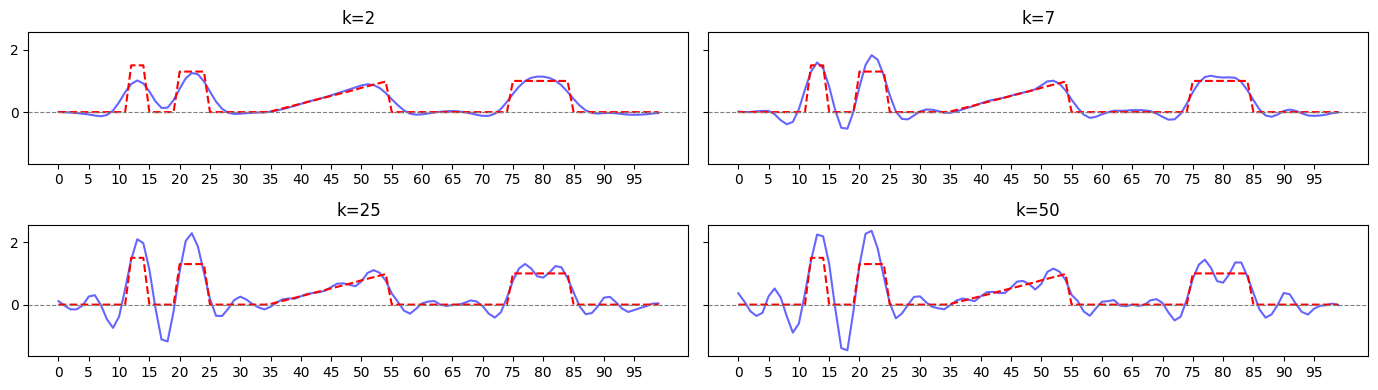

In [68]:
AtA = A.T @ A
eig_val, eig_vec = np.linalg.eigh(AtA)
kvals = [2, 7, 25, 50]
beta = 1 / eig_val[-1]**2

def LW_iterative(x, A, y, b):
  AtA = A.T @ A
  x_sol = x + b*(A.T @ y - AtA @ x)
  return x_sol

def iterate(A, y, beta, kvals):
  results = {}
  for k in kvals:
    temp_res = []
    x_curr = np.zeros(A.shape[1])
    for i in range(0, k):
      x_curr = LW_iterative(x_curr, A, y, beta)
      temp_res.append(x_curr)
    results[k] = temp_res
  return results

results = iterate(A, y, beta, kvals)
idx = np.arange(A.shape[1])
# plot the results
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14,4), sharey=True, squeeze=False)
# k = 2
axes[0,0].plot(idx, results[2][-1], 'b-', alpha=0.6)
axes[0,0].plot(idx, gt, "r--")
axes[0,0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0,0].set_title("k=2")
axes[0,0].set_xticks(idx[::5])
# k = 7
axes[0,1].plot(idx, results[7][-1], 'b-', alpha=0.6)
axes[0,1].plot(idx, gt, "r--")
axes[0,1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0,1].set_title("k=7")
axes[0,1].set_xticks(idx[::5])
# k = 25
axes[1,0].plot(idx, results[25][-1], 'b-', alpha=0.6)
axes[1,0].plot(idx, gt, "r--")
axes[1,0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1,0].set_title("k=25")
axes[1,0].set_xticks(idx[::5])
# k = 50
axes[1,1].plot(idx, results[50][-1], 'b-', alpha=0.6)
axes[1,1].plot(idx, gt, "r--")
axes[1,1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1,1].set_title("k=50")
axes[1,1].set_xticks(idx[::5])
plt.tight_layout()
plt.show()

___
## Task 3 (Morozov discrepancy)
Try to figure out the size (norm) of the measurement noise in vector `y`. What are the parameters $k$ and $\alpha$ in the previous two exercises that are indicated by the Morozov discrepancy rule? A rough answer is ok.

In [94]:
C = 100
alpha_set = np.linspace(1,1e-4, C)
noise_esti = A @ gt - y
delta = np.linalg.norm(noise_esti)
AtA = A.T @ A
eig_val, eig_vec = np.linalg.eigh(AtA)
beta = 1 / eig_val[-1]**2
# residuals initiatilization
resi_a = np.zeros(C)
k_opts = np.arange(1,51)
resi_L = np.zeros(len(k_opts))
# iterate
id = 0
for a in alpha_set:
  # for tikhonov regularisation
  x_alpha = tikho_regusol(A, y, a)
  resi_a[id] = np.linalg.norm(A @ x_alpha - y)
  id += 1

alpha_opti = alpha_set[np.argmin(np.abs(resi_a - delta))]
x_T = tikho_regusol(A, y, alpha_opti)
# for Landweber iteration
results_LW = iterate(A, y, beta, k_opts)
for idx, k in enumerate(k_opts):
  x_final = results_LW[k][-1]
  resi_L[idx] = np.linalg.norm(A @ x_final - y)
K_opt_L = k_opts[np.argmin(np.abs(resi_L - delta))]
new_k = list(np.arange(K_opt_L+1))
x_L = iterate(A, y, beta, new_k)
x_L.keys()

dict_keys([np.int64(0), np.int64(1), np.int64(2), np.int64(3)])

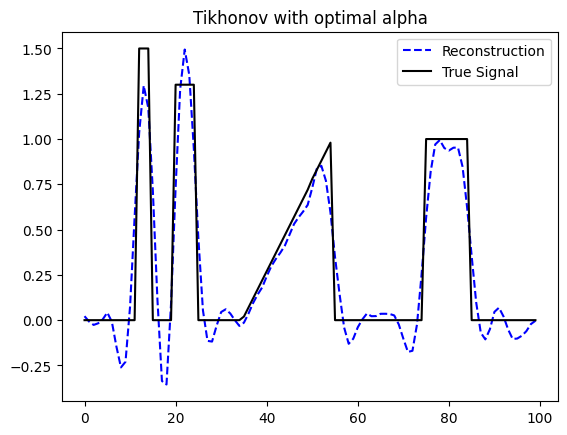

In [81]:
plt.plot(x_T, "b--", gt, 'k')
plt.title("Tikhonov with optimal alpha")
plt.legend(["Reconstruction", "True Signal"])
plt.show()

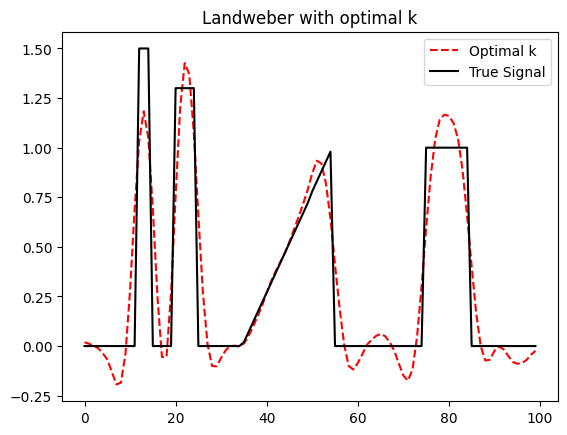

In [95]:
plt.plot(x_L[3][-1], "r--", gt, 'k')
plt.title("Landweber with optimal k")
plt.legend(["Optimal k", "True Signal"])
plt.show()